# 3 · Realistic-strength training: what erodes, and does replay repair it?

**Regime.** AdamW with full-precision master weights, 16-bit compute, 16k-token batches, 20-step warm-up then
inverse-square-root decay (Kaggle, `e2_worker.py`). All four skills are read at every skill checkpoint: instruction
following, hard tool calling, maths (GSM8K), and chart reading (ChartQA, image input).

**Sections appear only for results that exist.** (1) lr 2e-5 on code and chat-like data (have). (2) Replay on code at
lr 2e-5: no replay vs fixed vs triggered (`R2-W1-R3_dose_response_narrow_replay_forecast_test_kaggle.ipynb`). (3) Dose–response at lr 2e-6 and 5e-6.
(4) The pre-registered checks (`docs/preregistration.md`).

In [1]:
import sys, os; sys.path.insert(0, ".")
import numpy as np, pandas as pd
from kwm import *
setup(); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
import glob
SE = {"instruction_prompt": "instruction_se", "maths": "maths_se", "tools_correct": "tools_se", "charts": "charts_se"}
jobs = {}
for f in sorted(glob.glob(os.path.join(RES, "erosion", "R[12]_*.json")) + glob.glob(os.path.join(RES, "repair", "W1_*.json"))):
    if "_all_" in f: continue
    R = json.load(open(f)); jobs[(R[0]["arm"], R[0]["lr"], R[0]["replay_mode"])] = R
DATA = {"ood": "code", "benign": "chat-like"}
print("runs found:", ", ".join(f"{DATA[a]} lr {l:g} {r} (to {jobs[(a, l, r)][-1]['tokens']:,} tokens)" for a, l, r in sorted(jobs)))
lostpct = lambda r, k: 100 * (1 - r[k])
def skills_at(R, tokens=None):
    rows = [r for r in R if r.get("skills") and (tokens is None or r["tokens"] == tokens)]
    return rows[-1] if rows else None

runs found: chat-like lr 2e-06 none (to 2,015,232 tokens), chat-like lr 5e-06 none (to 2,015,232 tokens), chat-like lr 2e-05 none (to 2,015,232 tokens), code lr 2e-06 none (to 2,015,232 tokens), code lr 5e-06 none (to 2,015,232 tokens), code lr 2e-05 fixed (to 4,014,080 tokens), code lr 2e-05 none (to 4,014,080 tokens), code lr 2e-05 triggered (to 4,014,080 tokens)


## 1 · lr 2e-5: code vs chat-like data

In [2]:
base = {a: jobs[(a, 2e-5, "none")] for a in ("ood", "benign") if (a, 2e-5, "none") in jobs}
rows = []
for a, R in base.items():
    for r in R:
        rows.append({"data": DATA[a], "tokens": f"{r['tokens']:,}", "wrapped refusal lost %": round(lostpct(r, "kept_text_wrap"), 1),
                     "image refusal lost %": round(lostpct(r, "kept_image_wrap"), 1), "ARC": round(r["arc_text"], 2),
                     "held-out chat loss": round(r["ppl_ratio"], 2), "held-out code loss": round(r["ppl_code_ratio"], 2)})
pd.DataFrame(rows).set_index(["data", "tokens"])

wrapped refusal lost %  image refusal lost %   ARC  held-out chat loss  held-out code loss
data      tokens                                                                                               
code      507,904                      25.3                  35.2  0.84                1.02                1.18
          1,015,808                    20.5                  31.3  0.86                1.06                1.10
          2,015,232                    18.5                  24.5  0.84                1.03                0.98
          4,014,080                    25.7                  25.1  0.86                1.05                0.96
chat-like 507,904                      89.8                  96.4  0.26                0.71                1.06
          1,015,808                    95.2                  97.9  0.24                0.67                1.08
          2,015,232                    94.1                  97.5  0.28                0.65                1.09

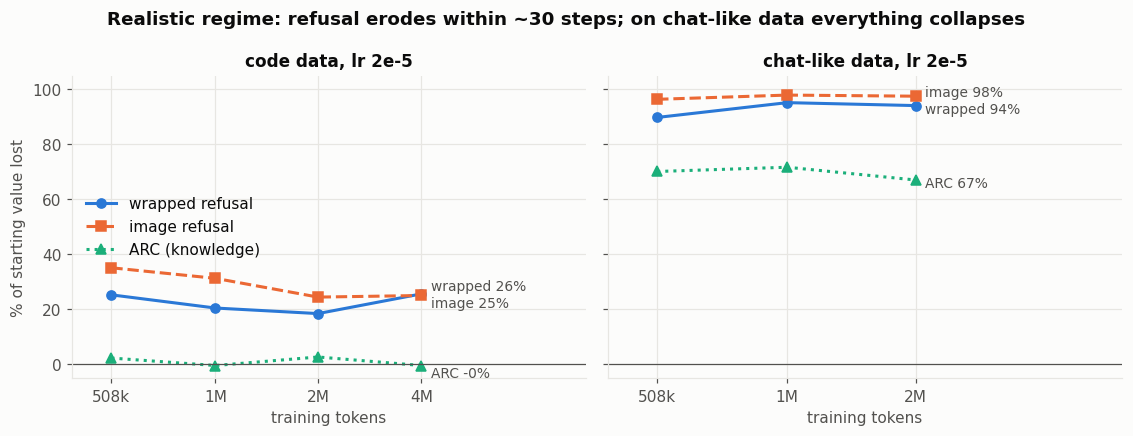

In [3]:
fig, axes = plt.subplots(1, len(base), figsize=(5.2 * len(base), 4), sharey=True, squeeze=False)
for ax, (a, R) in zip(axes[0], base.items()):
    t = [r["tokens"] for r in R]; a0 = R[0]["baseline"]["arc_text"]; ends = []
    for y, lab, col, ls, mk in (([lostpct(r, "kept_text_wrap") for r in R], "wrapped refusal", BLUE, "-", "o"),
                                ([lostpct(r, "kept_image_wrap") for r in R], "image refusal", ORANGE, "--", "s"),
                                ([100 * (1 - r["arc_text"] / a0) for r in R], "ARC (knowledge)", AQUA, ":", "^")):
        ax.plot(t, y, color=col, ls=ls, marker=mk, label=lab); ends.append((y[-1], f"{lab.split()[0]} {y[-1]:.0f}%"))
    end_labels(ax, t[-1], ends, gap=6); ax.axhline(0, color=INK2, lw=0.8); ax.set_ylim(-5, 105)
    tok_axis(ax, t); ax.set_xlim(t[0] / 1.3, t[-1] * 3); ax.set_title(f"{DATA[a]} data, lr 2e-5"); ax.set_xlabel("training tokens")
axes[0][0].set_ylabel("% of starting value lost"); axes[0][0].legend(loc="center left")
fig.suptitle("Realistic regime: refusal erodes within ~30 steps; on chat-like data everything collapses", fontweight="bold")
fig.tight_layout(); plt.show()

start  at 1M  change, pts  in SEs
data      skill                                         
code      instruction   0.57   0.36        -21.2    -5.4
          maths         0.38   0.10        -28.3    -6.4
          tools         0.69   0.78          9.4     2.0
          charts        0.70   0.00        -70.0   -15.3
chat-like instruction   0.57   0.11        -46.9   -12.0
          maths         0.38   0.00        -38.3    -8.6
          tools         0.69   0.00        -68.8   -14.5
          charts        0.70   0.00        -70.0   -15.3

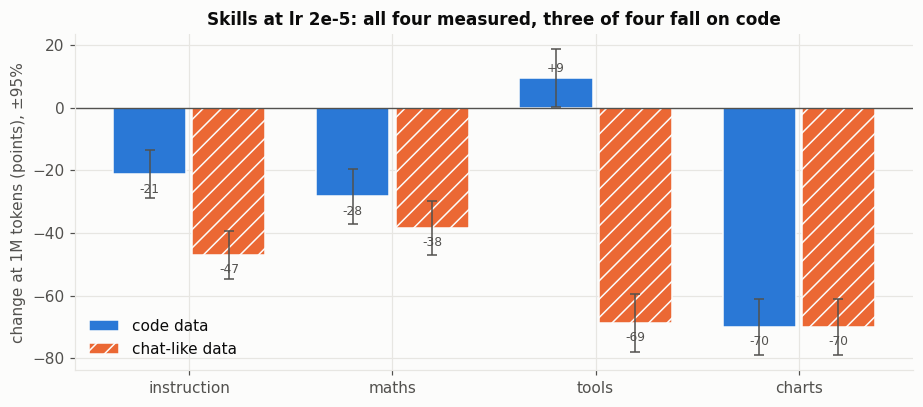

In [4]:
rows = []
for a, R in base.items():
    r = skills_at(R, 1015808); sb = R[0]["skills_baseline"]
    if r is None: continue
    for k in SKILLS:
        rows.append({"data": DATA[a], "skill": k.split("_")[0], "start": round(sb[k], 2), "at 1M": round(r["skills"][k], 2),
                     "change, pts": round(100 * (r["skills"][k] - sb[k]), 1), "in SEs": round((r["skills"][k] - sb[k]) / max(sb[SE[k]], 1e-9), 1)})
S1 = pd.DataFrame(rows); display(S1.set_index(["data", "skill"]))
fig, ax = plt.subplots(figsize=(8.5, 3.8)); x, w = np.arange(len(SKILLS)), 0.36
for i, (a, col, ht) in enumerate((("ood", BLUE, ""), ("benign", ORANGE, "//"))):
    if a not in base: continue
    d = S1[S1.data == DATA[a]]; v = d["change, pts"].values
    se = [196 * base[a][0]["skills_baseline"][SE[k]] for k in SKILLS]
    xx = x + (i - 0.5) * (w + 0.03)
    ax.bar(xx, v, width=w, color=col, hatch=ht, edgecolor=SURFACE, label=f"{DATA[a]} data"); ax.errorbar(xx, v, yerr=se, fmt="none", ecolor=INK2, capsize=3, lw=1)
    for xi, vi in zip(xx, v): ax.annotate(f"{vi:+.0f}", (xi, vi), xytext=(0, 4 if vi >= 0 else -12), textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=0.9); ax.set_xticks(x); ax.set_xticklabels([k.split("_")[0] for k in SKILLS])
ax.set_ylabel("change at 1M tokens (points), ±95%"); ax.legend(loc="lower left"); ax.set_title("Skills at lr 2e-5: all four measured, three of four fall on code")
fig.tight_layout(); plt.show()

**Reading it.** On code, knowledge holds while refusal and three of four skills fall: P1, now including skills.
Tool calling does not fall. Chart reading at exactly 0 while image-ARC holds, and ARC at chance on chat-like data, are
most likely *format* collapse: the model stops answering in the requested form. The new format rates in the next runs
separate the two. Erosion is a jump in the first ~30 steps, then a plateau, not the log-linear decay of the gentle
regime (THESIS_LOG entry 23).

## 2 · Replay on code data at lr 2e-5

wrapped kept  image kept   ARC  held-out code loss replay tokens
replay    tokens                                                                     
none      507,904           0.747       0.648  0.84               1.185             0
          1,015,808         0.795       0.687  0.86               1.100             0
          2,015,232         0.815       0.755  0.84               0.976             0
          4,014,080         0.743       0.749  0.86               0.957             0
fixed     507,904           0.753       0.552  0.83               1.078       158,720
          1,015,808         1.015       0.760  0.85               1.247       317,440
          2,015,232         1.033       0.510  0.84               1.000       629,760
          4,014,080         1.185       0.679  0.83               0.972     1,254,400
triggered 507,904           0.747       0.648  0.84               1.184             0
          1,015,808         1.065       1.145  0.87               1.100        65,536
          2,015,232         0.924       1.104  0.86               0.982        65,536
          4,014,080         0.887       1.064  0.86               0.958        65,536

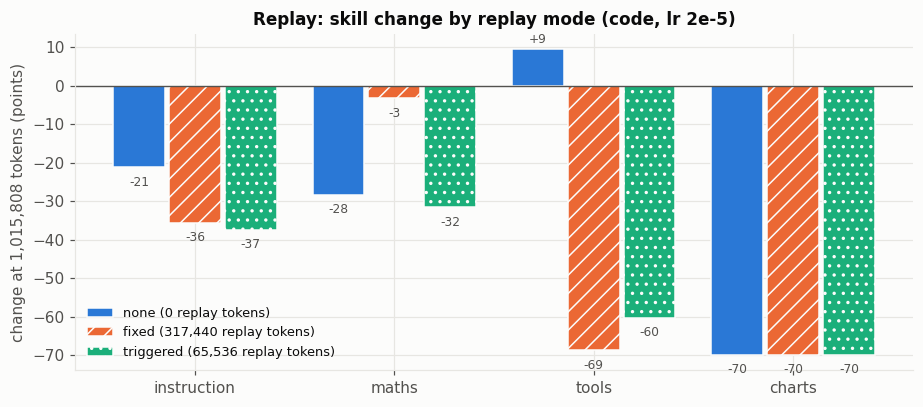

In [5]:
arms = [m for m in ("none", "fixed", "triggered") if ("ood", 2e-5, m) in jobs]
if arms == ["none"] or not arms:
    print("replay runs pending (R2-W1-R3_dose_response_narrow_replay_forecast_test_kaggle.ipynb) -- only the no-replay reference exists")
else:
    shared = sorted(set.intersection(*[{r["tokens"] for r in jobs[("ood", 2e-5, m)]} for m in arms]))
    rows = []
    for m in arms:
        R = {r["tokens"]: r for r in jobs[("ood", 2e-5, m)]}
        for t in shared:
            r = R[t]; rows.append({"replay": m, "tokens": f"{t:,}", "wrapped kept": round(r["kept_text_wrap"], 3), "image kept": round(r["kept_image_wrap"], 3),
                                   "ARC": round(r["arc_text"], 2), "held-out code loss": round(r["ppl_code_ratio"], 3), "replay tokens": f"{r['replay_tokens']:,}"})
    display(pd.DataFrame(rows).set_index(["replay", "tokens"]))
    t_sk = max(set.intersection(*[{r["tokens"] for r in jobs[("ood", 2e-5, m)] if r.get("skills")} for m in arms]))
    sb = jobs[("ood", 2e-5, "none")][0]["skills_baseline"] if "none" in arms else jobs[("ood", 2e-5, arms[0])][0]["skills_baseline"]
    fig, ax = plt.subplots(figsize=(8.5, 3.8)); x, w = np.arange(len(SKILLS)), 0.26
    for i, (m, col, ht) in enumerate(zip(arms, (BLUE, ORANGE, AQUA), ("", "//", ".."))):
        r = skills_at(jobs[("ood", 2e-5, m)], t_sk); v = [100 * (r["skills"][k] - sb[k]) for k in SKILLS]; xx = x + (i - (len(arms) - 1) / 2) * (w + 0.02)
        ax.bar(xx, v, width=w, color=col, hatch=ht, edgecolor=SURFACE, label=f"{m} ({r['replay_tokens']:,} replay tokens)")
        for xi, vi in zip(xx, v): ax.annotate(f"{vi:+.0f}", (xi, vi), xytext=(0, 4 if vi >= 0 else -12), textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.axhline(0, color=INK2, lw=0.9); ax.set_xticks(x); ax.set_xticklabels([k.split("_")[0] for k in SKILLS]); ax.legend(fontsize=8.5)
    ax.set_ylabel(f"change at {t_sk:,} tokens (points)"); ax.set_title("Replay: skill change by replay mode (code, lr 2e-5)"); fig.tight_layout(); plt.show()

## 3 · Dose–response: which behaviour breaks first as strength rises

In [6]:
rates = sorted({l for (a, l, m) in jobs if m == "none"})
if rates == [2e-5]:
    print("dose–response runs pending (lr 2e-6, 5e-6 in R2-W1-R3_dose_response_narrow_replay_forecast_test_kaggle.ipynb)")
else:
    rows = []
    for a in ("ood", "benign"):
        for l in rates:
            R = jobs.get((a, l, "none"))
            if not R: continue
            r = min(R, key=lambda r: abs(r["tokens"] - 2015232)); sk = skills_at([x for x in R if x["tokens"] <= r["tokens"]]); sb = R[0]["skills_baseline"]
            row = {"data": DATA[a], "lr": l, "tokens": f"{r['tokens']:,}", "wrapped lost %": round(lostpct(r, "kept_text_wrap"), 1),
                   "image lost %": round(lostpct(r, "kept_image_wrap"), 1), "ARC change": round(100 * (r["arc_text"] - r["baseline"]["arc_text"]), 1)}
            if sk: row.update({f"{k.split('_')[0]} Δ (SE)": round((sk["skills"][k] - sb[k]) / max(sb[SE[k]], 1e-9), 1) for k in SKILLS})
            rows.append(row)
    display(pd.DataFrame(rows).set_index(["data", "lr"]))

tokens  wrapped lost %  image lost %  ARC change  instruction Δ (SE)  maths Δ (SE)  tools Δ (SE)  charts Δ (SE)
data      lr                                                                                                                          
code      0.000002  2,015,232             6.8           9.4         0.3                 0.2          -1.1           2.0            0.0
          0.000005  2,015,232             9.2          13.6         0.3                -0.8           0.0           1.1           -0.4
          0.000020  2,015,232            18.5          24.5        -2.3                -5.4          -6.4           2.0          -15.3
chat-like 0.000002  2,015,232            18.3           8.3        -3.7                -7.2          -6.6          -7.5          -15.3
          0.000005  2,015,232            40.5          47.1       -13.3                -8.6           0.8         -12.1          -14.6
          0.000020  2,015,232            94.1          97.5       -57.7               -12.0          -8.6         -14.5          -15.3

**Format or ability?** The newer runs also record whether answers came in the requested form (maths: an `Answer: <number>` line; charts: a single word or number; tools: a parseable call). When accuracy collapses together with format, the model has stopped answering in the requested form. That doesn't show it lost the underlying ability.

In [7]:
rows = []
for (a, l, m), R in sorted(jobs.items()):
    for r in R:
        s = r.get("skills")
        if not s or "charts_format" not in s: continue
        rows.append({"data": DATA[a], "lr": l, "replay": m, "tokens": f"{r['tokens']:,}",
                     "charts acc": round(s["charts"], 2), "charts format": round(s["charts_format"], 2),
                     "tools correct": round(s["tools_correct"], 2), "tools valid call": round(s["tools_valid"], 2),
                     "maths acc": round(s["maths"], 2), "maths format": round(s["maths_format"], 2)})
F = pd.DataFrame(rows).set_index(["data", "lr", "replay", "tokens"]); F

charts acc  charts format  tools correct  tools valid call  maths acc  maths format
data      lr       replay    tokens                                                                                        
chat-like 0.000002 none      262,144          0.69           0.98           0.65              0.83       0.33          0.43
                             1,015,808        0.03           0.38           0.45              0.54       0.31          0.48
                             2,015,232        0.00           0.05           0.33              0.40       0.09          0.60
          0.000005 none      262,144          0.68           0.98           0.55              0.62       0.35          0.50
                             1,015,808        0.02           0.04           0.11              0.20       0.28          0.75
                             2,015,232        0.03           0.07           0.11              0.16       0.42          0.80
code      0.000002 none      262,144          0.70           0.99           0.68              0.86       0.32          0.43
                             1,015,808        0.70           0.99           0.75              0.86       0.34          0.45
                             2,015,232        0.70           0.99           0.78              0.90       0.33          0.42
          0.000005 none      262,144          0.70           0.99           0.76              0.91       0.35          0.49
                             1,015,808        0.69           0.99           0.80              0.92       0.36          0.51
                             2,015,232        0.68           0.99           0.74              0.92       0.38          0.41
          0.000020 fixed     262,144          0.00           0.00           0.17              0.17       0.11          0.54
                             1,015,808        0.00           0.00           0.00              0.00       0.35          0.52
                             4,014,080        0.00           0.00           0.08              0.18       0.25          0.54
                   triggered 262,144          0.45           0.71           0.78              0.90       0.23          0.50
                             1,015,808        0.00           0.00           0.08              0.17       0.07          0.56
                             4,014,080        0.00           0.02           0.00              0.17       0.05          0.69

Chart accuracy falls with chart *format* (short answers 0.98 → 0.0–0.07): the zeros are format collapse. Tool calling falls with call *validity*. Maths is the exception: format rises (0.41 → 0.6–0.8) while accuracy falls, so the model still writes the answer line but gets the maths wrong, and there ability is lost.

## 4 · Pre-registered checks (only those with data)

In [8]:
def V(ok): return "PASS" if ok else "FAIL"
out, pending = [], []
N = jobs.get(("ood", 2e-5, "none"))
for m in ("fixed", "triggered"):                       # section 2 (P3, revised condition: code, lr 2e-5)
    X = jobs.get(("ood", 2e-5, m))
    if not (N and X): pending.append(f"P3 ({m})"); continue
    n, x = {r["tokens"]: r for r in N}, {r["tokens"]: r for r in X}; t = max(set(n) & set(x))
    ln = {c: 1 - n[t]["kept_" + c] for c in ("text_wrap", "image_wrap")}; Rc = {c: (x[t]["kept_" + c] - n[t]["kept_" + c]) / ln[c] for c in ln}
    testable = min(ln.values()) >= 0.05 and Rc["text_wrap"] >= 0.2; ratio = Rc["image_wrap"] / Rc["text_wrap"] if Rc["text_wrap"] else float("nan")
    out.append(f"[P3 {m}] at {t:,}: restoration text {Rc['text_wrap']:+.2f}, image {Rc['image_wrap']:+.2f}, ratio {ratio:.2f} -> "
               + ("NOT TESTABLE" if not testable else ("REFUTED" if ratio >= 1.0 else ("INCONCLUSIVE" if ratio > 0.85 else
                  ("PASS by the rule only -- image refusal was made WORSE, not partly restored" if Rc["image_wrap"] < 0 else "PASS")))))
F, T = jobs.get(("ood", 2e-5, "fixed")), jobs.get(("ood", 2e-5, "triggered"))
if F and T:                                            # 3f
    fs, ts = skills_at(F), skills_at(T); gap = {k.split("_")[0]: 100 * (ts["skills"][k] - fs["skills"][k]) for k in SKILLS}
    out.append(f"[3f] replay tokens triggered {T[-1]['replay_tokens']:,} vs fixed {F[-1]['replay_tokens']:,}; skill gap (pts) {gap} -> "
               + V(T[-1]["replay_tokens"] < F[-1]["replay_tokens"] and all(v >= -2 for v in gap.values())))
else: pending.append("3f")
def at2M(R): return min(R, key=lambda r: abs(r["tokens"] - 2015232))
for l in (2e-6, 5e-6):                                 # D1
    if ("ood", l, "none") in jobs and ("benign", l, "none") in jobs:
        c, h = lostpct(at2M(jobs[("ood", l, "none")]), "kept_text_wrap"), lostpct(at2M(jobs[("benign", l, "none")]), "kept_text_wrap")
        out.append(f"[D1] lr {l:g}: wrapped lost at 2M, code {c:.1f}% vs chat-like {h:.1f}% -> {V(h > c)}")
    else: pending.append(f"D1 lr {l:g}")
for a in ("ood", "benign"):                            # D2
    if all((a, l, "none") in jobs for l in (2e-6, 5e-6, 2e-5)):
        v = [lostpct(at2M(jobs[(a, l, "none")]), "kept_text_wrap") for l in (2e-6, 5e-6, 2e-5)]
        out.append(f"[D2] {DATA[a]}: wrapped lost at 2M for 2e-6 / 5e-6 / 2e-5 = {v[0]:.1f} / {v[1]:.1f} / {v[2]:.1f}% -> {V(v[0] < v[1] < v[2])}")
    else: pending.append(f"D2 {DATA[a]}")
    R = jobs.get((a, 2e-6, "none"))                    # D3
    if R:
        sb = R[0]["skills_baseline"]; pts = [r for r in R if r.get("skills")]
        first_ref = next((r["tokens"] for r in pts if lostpct(r, "kept_text_wrap") >= 5), None)
        first_sk = next((r["tokens"] for r in pts if any((r["skills"][k] - sb[k]) / max(sb[SE[k]], 1e-9) < -1.96 for k in SKILLS)), None)
        if first_ref is None and first_sk is None: out.append(f"[D3] {DATA[a]} lr 2e-6: neither moved by 2M -> NOT TESTABLE")
        else: out.append(f"[D3] {DATA[a]} lr 2e-6: refusal first at {first_ref}, skills first at {first_sk} -> "
                         + V(first_ref is not None and (first_sk is None or first_ref <= first_sk)))
    else: pending.append(f"D3 {DATA[a]}")
for l in (2e-6, 5e-6):                                 # D4
    R = jobs.get(("ood", l, "none"))
    if R: d = max(abs(100 * (r["arc_text"] - r["baseline"]["arc_text"])) for r in R); out.append(f"[D4] code lr {l:g}: max ARC change {d:.1f} pts -> {V(d <= 5)}")
    else: pending.append(f"D4 lr {l:g}")
print("\n".join(out) if out else "no pre-registered check has data yet")
if pending: print("\npending (no data yet):", ", ".join(pending))

[P3 fixed] at 4,014,080: restoration text +1.72, image -0.28, ratio -0.16 -> PASS by the rule only -- image refusal was made WORSE, not partly restored
[P3 triggered] at 4,014,080: restoration text +0.56, image +1.26, ratio 2.24 -> REFUTED
[3f] replay tokens triggered 65,536 vs fixed 1,254,400; skill gap (pts) {'instruction': 8.124999999999998, 'maths': -20.0, 'tools': -8.333333333333332, 'charts': 0.0} -> FAIL
[D1] lr 2e-06: wrapped lost at 2M, code 6.8% vs chat-like 18.3% -> PASS
[D1] lr 5e-06: wrapped lost at 2M, code 9.2% vs chat-like 40.5% -> PASS
[D2] code: wrapped lost at 2M for 2e-6 / 5e-6 / 2e-5 = 6.8 / 9.2 / 18.5% -> PASS
[D3] code lr 2e-6: refusal first at 262144, skills first at None -> PASS
[D2] chat-like: wrapped lost at 2M for 2e-6 / 5e-6 / 2e-5 = 18.3 / 40.5 / 94.1% -> PASS
[D3] chat-like lr 2e-6: refusal first at 262144, skills first at 1015808 -> PASS
[D4] code lr 2e-06: max ARC change 0.7 pts -> PASS
[D4] code lr 5e-06: max ARC change 1.0 pts -> PASS
